In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, f1_score
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

In [17]:
df = pd.read_csv(r"D:\DATA\aitpune\college study thingy\ml\dataset\Churn_Modelling.csv")
print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [18]:
print('Dataset shape:', df.shape)

Dataset shape: (10000, 14)


In [19]:
print(df['Exited'].value_counts())

Exited
0    7963
1    2037
Name: count, dtype: int64


In [20]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

In [21]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], dtype=int)

In [22]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Training:', X_train.shape)
print('Testing:', X_test.shape)

Training: (8000, 13)
Testing: (2000, 13)


In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [25]:
tf.keras.utils.set_random_seed(42)

normal_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [26]:
normal_model.compile(optimizer='adam',
                     loss='binary_crossentropy',
                     metrics=['accuracy'])


In [28]:
normal_history = normal_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8673 - loss: 0.3227
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8675 - loss: 0.3224
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8673 - loss: 0.3222
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8673 - loss: 0.3221
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8675 - loss: 0.3219
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8676 - loss: 0.3217
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8676 - loss: 0.3215
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8675 - loss: 0.3214
Epoch 9/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8681 - loss: 0.3212
Epoch 10/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8679 - loss: 0.3211
Epoch 11/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8679 - loss: 0.3209
Epoch 12/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [29]:
normal_pred = (normal_model.predict(X_test, verbose=0) >= 0.5).astype(int).ravel()

In [30]:
tf.keras.utils.set_random_seed(42)

improved_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [31]:
improved_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
improved_history = improved_model.fit(X_train, y_train, epochs=50, batch_size=32,
                   class_weight={0: 1, 1: 2}, verbose=1)

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7318 - loss: 0.7457
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7916 - loss: 0.6501
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8026 - loss: 0.6065
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8190 - loss: 0.5745
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8296 - loss: 0.5520
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8331 - loss: 0.5377
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8347 - loss: 0.5287
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8374 - loss: 0.5227
Epoch 9/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8386 - loss: 0.5182
Epoch 10/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8399 - loss: 0.5146
Epoch 11/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8403 - loss: 0.5119
Epoch 12/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [32]:
improved_pred = (improved_model.predict(X_test, verbose=0) >= 0.5).astype(int).ravel()

In [33]:
comparison = pd.DataFrame({
    'Model': ['Normal ANN', 'Improved ANN'],
    'Accuracy (%)': [round(accuracy_score(y_test, normal_pred) * 100, 2),
                     round(accuracy_score(y_test, improved_pred) * 100, 2)],
    'Churn Recall (%)': [round(recall_score(y_test, normal_pred) * 100, 2),
                         round(recall_score(y_test, improved_pred) * 100, 2)],
    'Churn F1': [round(f1_score(y_test, normal_pred), 3),
                 round(f1_score(y_test, improved_pred), 3)]
})
print(comparison.to_string(index=False))

       Model  Accuracy (%)  Churn Recall (%)  Churn F1
  Normal ANN         86.15             48.16     0.586
Improved ANN         85.05             63.14     0.632


In [34]:
print('\nNormal ANN confusion matrix:')
print(confusion_matrix(y_test, normal_pred))
print('\nImproved ANN confusion matrix:')
print(confusion_matrix(y_test, improved_pred))

print('\nActual churners correctly identified:')
print('Normal ANN:', confusion_matrix(y_test, normal_pred)[1, 1])
print('Improved ANN:', confusion_matrix(y_test, improved_pred)[1, 1])


Normal ANN confusion matrix:
[[1527   66]
 [ 211  196]]

Improved ANN confusion matrix:
[[1444  149]
 [ 150  257]]

Actual churners correctly identified:
Normal ANN: 196
Improved ANN: 257


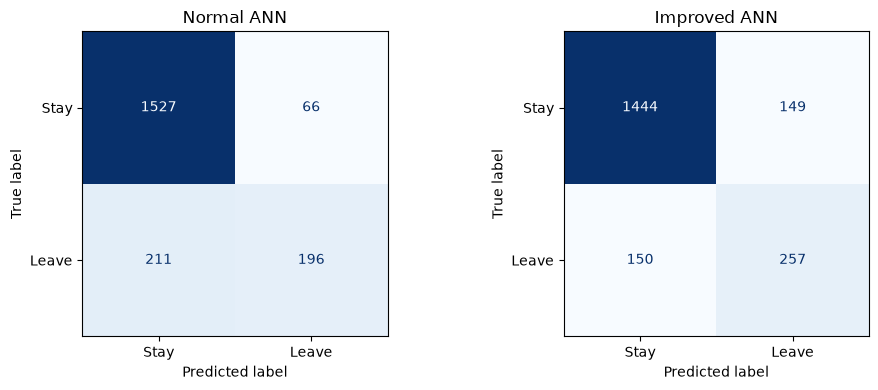

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, normal_pred,
    display_labels=['Stay', 'Leave'], cmap='Blues', colorbar=False, ax=ax[0])
ConfusionMatrixDisplay.from_predictions(y_test, improved_pred,
    display_labels=['Stay', 'Leave'], cmap='Blues', colorbar=False, ax=ax[1])
ax[0].set_title('Normal ANN')
ax[1].set_title('Improved ANN')
plt.tight_layout()
plt.show()

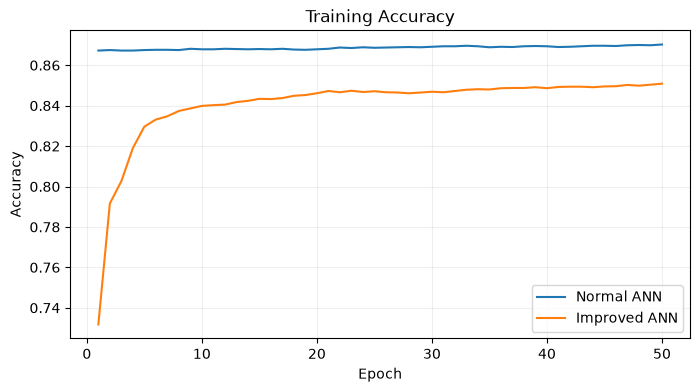

In [36]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 51), normal_history.history['accuracy'], label='Normal ANN')
plt.plot(range(1, 51), improved_history.history['accuracy'], label='Improved ANN')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

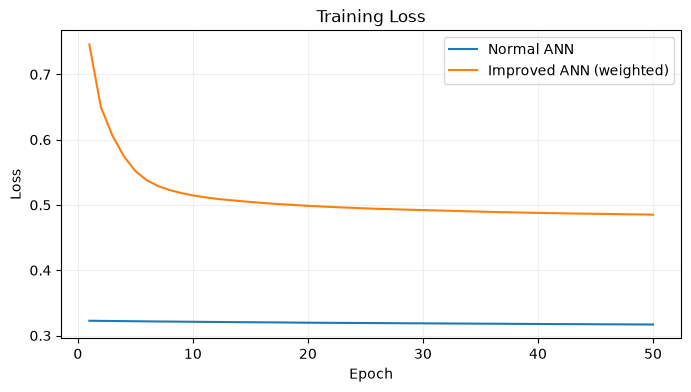

In [37]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 51), normal_history.history['loss'], label='Normal ANN')
plt.plot(range(1, 51), improved_history.history['loss'], label='Improved ANN (weighted)')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

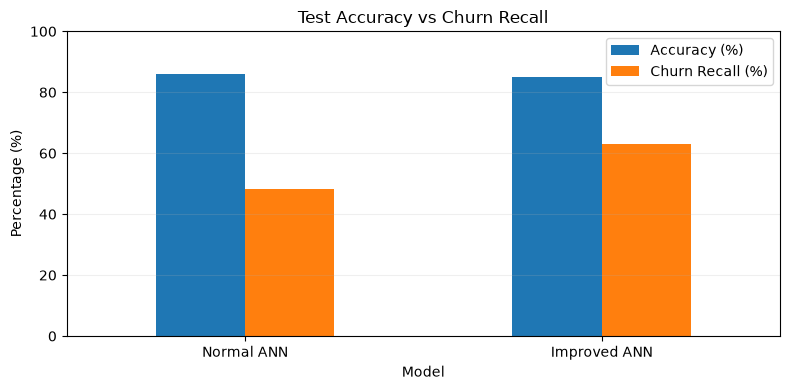

In [38]:
comparison.plot(x='Model', y=['Accuracy (%)', 'Churn Recall (%)'],
                kind='bar', figsize=(8, 4))
plt.title('Test Accuracy vs Churn Recall')
plt.ylabel('Percentage (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()